# Ensemble Learning with Random Forests

**Objective:** Implement Random Forest models and understand how combining decision trees can improve predictive performance and generalization.

This experiment uses synthetic datasets generated with scikit-learn, so it runs in Colab without external data. Run cells from top to bottom.

## Learning outcomes

By completing this experiment, you will be able to:
1. Explain ensemble learning, bootstrap sampling, and random feature selection.
2. Train Random Forest classifiers and regressors.
3. Compare a Random Forest with a single decision tree.
4. Evaluate generalization using held-out data and cross-validation.
5. Interpret feature importance and examine model complexity.

In [5]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('Imports complete.')

Imports complete.


## 1. What is Random Forest?

A Random Forest builds many decision trees using bootstrap samples of the training data. At each split, each tree considers a random subset of features.

- **Classification:** trees vote for a class.
- **Regression:** tree predictions are averaged.
- Combining diverse trees can reduce variance compared with relying on one deep tree.
- The number of trees (`n_estimators`), maximum depth (`max_depth`), and number of features considered at a split (`max_features`) affect model behavior.

## 2. Classification experiment

We generate a binary classification dataset and split it into training and test sets. The test set is held out for final evaluation.

In [6]:
X, y = make_classification(
    n_samples=1200, n_features=12, n_informative=6, n_redundant=2,
    n_classes=2, class_sep=1.0, flip_y=0.04, random_state=RANDOM_STATE
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Training samples:', len(y_train), '| Test samples:', len(y_test))
print('Class counts in full dataset:', np.bincount(y))

Training samples: 900 | Test samples: 300
Class counts in full dataset: [602 598]


In [7]:
# Compare a single decision tree with Random Forest models
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest (10 trees)': RandomForestClassifier(n_estimators=10, random_state=RANDOM_STATE, n_jobs=-1),
    'Random Forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Random Forest (300 trees)': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'Model': name,
        'Train accuracy': model.score(X_train, y_train),
        'Test accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
    })
results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Train accuracy,Test accuracy,Precision,Recall,F1-score
0,Decision Tree,1.000,0.810,0.808,0.813,0.811
1,Random Forest (10 trees),0.992,0.847,0.882,0.800,0.839
2,Random Forest (100 trees),1.000,0.863,0.856,0.873,0.865
3,Random Forest (300 trees),1.000,0.867,0.862,0.873,0.868


### Evaluate the selected Random Forest

Inspect the classification report and confusion matrix. A false positive is a negative example predicted as positive; a false negative is a positive example predicted as negative.

              precision    recall  f1-score   support

           0      0.871     0.853     0.862       150
           1      0.856     0.873     0.865       150

    accuracy                          0.863       300
   macro avg      0.863     0.863     0.863       300
weighted avg      0.863     0.863     0.863       300



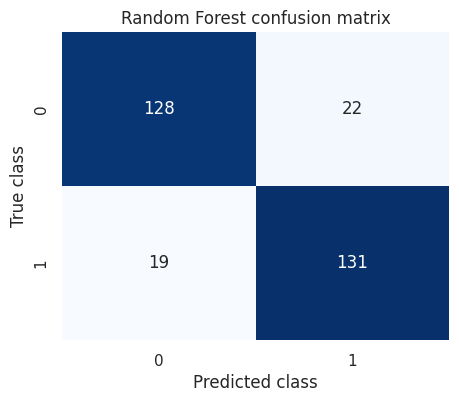

In [8]:
rf_classifier = models['Random Forest (100 trees)']
y_pred = rf_classifier.predict(X_test)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted class'); plt.ylabel('True class')
plt.title('Random Forest confusion matrix')
plt.show()

## 3. Feature importance

Random Forests estimate feature importance from how much each feature reduces impurity across the trees. This is a useful first inspection, but importance is not proof of causation and can be biased when features differ in scale or cardinality.

,Importance
Feature 11,0.2164
Feature 12,0.1484
Feature 4,0.1188
Feature 1,0.1007
Feature 2,0.0840
Feature 7,0.0809
Feature 8,0.0714
Feature 6,0.0629
Feature 9,0.0324
Feature 3,0.0286


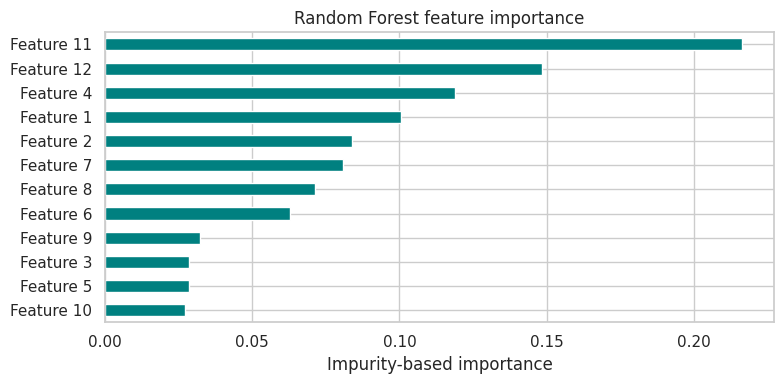

In [9]:
importance = pd.Series(rf_classifier.feature_importances_, index=[f'Feature {i+1}' for i in range(X.shape[1])])
importance = importance.sort_values(ascending=False)
display(importance.rename('Importance').to_frame().round(4))
plt.figure(figsize=(8, 4))
importance.sort_values().plot(kind='barh', color='teal')
plt.xlabel('Impurity-based importance'); plt.title('Random Forest feature importance')
plt.tight_layout(); plt.show()

## 4. Generalization and cross-validation

A single train/test split gives one estimate of performance. Cross-validation trains and validates the model across multiple splits of the training data. Here we compare 5-fold accuracy for a tree and a forest. The held-out test set remains separate.

In [3]:
cv_models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}
cv_rows = []
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_rows.append({'Model': name, 'Fold accuracies': np.round(scores, 3),
                    'Mean CV accuracy': scores.mean(), 'Std. deviation': scores.std()})
for row in cv_rows:
    print(row['Model'], '| folds:', row['Fold accuracies'],
          '| mean:', round(row['Mean CV accuracy'], 3),
          '| std:', round(row['Std. deviation'], 3))

NameError: name 'DecisionTreeClassifier' is not defined

## 5. Regression experiment

Random Forests can also predict continuous values. For regression, the forest averages the predictions from its trees. We compare a shallow and deeper forest using MAE, RMSE, and R².

In [10]:
X_reg, y_reg = make_regression(
    n_samples=1000, n_features=10, n_informative=6, noise=18, random_state=RANDOM_STATE
)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=RANDOM_STATE
)
reg_models = {
    'Shallow forest (max_depth=4)': RandomForestRegressor(n_estimators=150, max_depth=4, random_state=RANDOM_STATE, n_jobs=-1),
    'Unrestricted forest': RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
}
reg_rows = []
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_rows.append({'Model': name, 'MAE': mean_absolute_error(yr_test, pred),
                     'RMSE': np.sqrt(mean_squared_error(yr_test, pred)),
                     'R²': r2_score(yr_test, pred)})
display(pd.DataFrame(reg_rows).round(3))

,Model,MAE,RMSE,R²
0,Shallow forest (max_depth=4),21.633,27.517,0.846
1,Unrestricted forest,17.210,22.402,0.898


## 6. Observations

Use the outputs from your run to answer:
1. Did the Random Forest outperform the single decision tree on test data? Compare training and test accuracy.
2. What happened to performance as the number of trees increased? Did adding more trees always improve the score?
3. How consistent were the cross-validation scores for each model?
4. Which features were most important? What limitations should you consider when interpreting importance?
5. Compare the shallow and unrestricted regression forests using the reported metrics.

### Key idea
A Random Forest reduces reliance on one tree by averaging or voting across many trees trained with data and feature randomness. This often improves stability and generalization, though results depend on the dataset and settings.

## 7. Conclusion

This experiment implemented Random Forest classification and regression, compared forests with a single decision tree, evaluated predictions with multiple metrics, used cross-validation, and inspected feature importance. Random Forests are often strong general-purpose models for structured data, but they can be less interpretable and larger than a single tree.

## Student implementation questions

1. **Multiclass task:** Generate a dataset with at least three classes. Train a Random Forest classifier and report accuracy, macro precision, macro recall, macro F1, and a confusion matrix.
2. **Hyperparameter investigation:** Compare `max_features` values (for example, `1.0`, `"sqrt"`, and `0.5`) while keeping the train/test split fixed. Plot test F1-score against the setting and explain the result.
3. **Ensemble size and generalization:** Train forests with `n_estimators` values of 5, 20, 50, 100, and 300. Plot training and test accuracy. Discuss stability, generalization, and computation time as the forest grows.

## Optional extension

Use a real labeled dataset, such as a dataset available from `sklearn.datasets`. Document the dataset and target, perform a stratified train/test split for classification, compare a decision tree and Random Forest, and interpret the evaluation results. Tune hyperparameters using cross-validation on the training data only.